<a href="https://colab.research.google.com/github/NSPFD/Thai-quantum-computing-2026/blob/main/Thai_school_QC1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Installing necessary modules

In [ ]:
!pip install qiskit
!pip install qiskit_algorithms
!pip install qiskit_aer

In [ ]:
!pip install qiskit_ibm_runtime
!pip install pylatexenc

## 2. Quantum gates and Bloch Sphere with Qiskit

#### X gate

The X gate is a $\pi$ rotation around the $x$ axis of the Bloch sphere.
Applying the X gate to $|0\rangle$ results in $|1\rangle$, and applying the X gate to $|1\rangle$ results in $|0\rangle$, so it is an operation similar to the classical NOT gate, and is also known as bit flip. The matrix representation of the X gate is below.

$$
X = \begin{pmatrix}
0 & 1 \\
1 & 0 \\
\end{pmatrix}
$$

In IBM Quantum®, the initial state is set to $|0\rangle$, so the quantum circuit above in matrix representation is

$$
X|0\rangle=  \begin{pmatrix}
0 & 1 \\
1 & 0
\end{pmatrix}
\begin{pmatrix}
1 \\ 0
\end{pmatrix}
 =\begin{pmatrix}
0 \\ 1
\end{pmatrix} = |1\rangle
$$

Next, let's run this circuit using a statevector simulator.




In [ ]:
# Import core Qiskit classes
from qiskit import QuantumCircuit
# Import the Aer Simulator and visualization tools
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from qiskit.visualization import plot_bloch_multivector
from qiskit.quantum_info import Statevector


# Import the qiskit library
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector
from qiskit_ibm_runtime import SamplerV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.visualization import plot_histogram

In [ ]:
!pip install pylatexenc
!pip install matplotlib

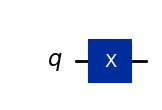

In [ ]:
qc = QuantumCircuit(1)  # Prepare the single-qubit quantum circuit

# Apply a X gate to qubit 0
qc.x(0)

# Draw the circuit
qc.draw("mpl")

Statevector([0.+0.j, 1.+0.j],
            dims=(2,))


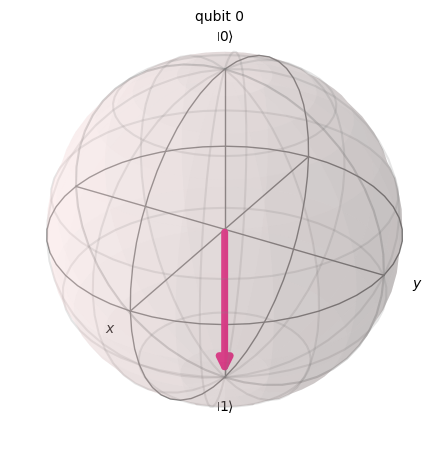

In [ ]:
# See the statevector
out_vector = Statevector(qc)
print(out_vector)

# Draw a Bloch sphere
plot_bloch_multivector(out_vector)

#### H gate

The Hadamard gate is a $\pi$ rotation around an axis halfway between the $x$ and $z$ axes on the Bloch sphere. Applying the H gate to $|0\rangle$ creates a superposition state such as $\frac{|0\rangle + |1\rangle}{\sqrt{2}}$. The matrix representation of the H gate is below.

$$
H = \frac{1}{\sqrt{2}}\begin{pmatrix}
1 & 1 \\
1 & -1 \\
\end{pmatrix}
$$


We can apply it to a $|0 \rangle$:

$$
H|0\rangle= \frac{1}{\sqrt{2}} \begin{pmatrix}
1 & 1 \\
1 & -1
\end{pmatrix}
\begin{pmatrix}
1 \\0
\end{pmatrix}
 =\frac{1}{\sqrt{2}}\begin{pmatrix}
1 \\
1
\end{pmatrix}
=\begin{pmatrix}
0.707 \\
0.707
\end{pmatrix}
=\frac{1}{\sqrt{2}}(|0\rangle+|1\rangle)
$$

This superposition state is so common and important, that it is given its own symbol:

$$
|+\rangle \equiv \frac{1}{\sqrt{2}}(|0\rangle+|1\rangle).
$$

By applying the $H$ gate on the $|0\rangle$, we created a superposition of $|0\rangle$ and $|1\rangle$ where measurement in the computational basis (along z in the Bloch sphere picture) would give you each state with equal probabilities.




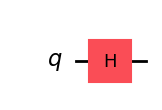

In [ ]:
qc = QuantumCircuit(1)  # Create the single-qubit quantum circuit

# Apply an Hadamard gate to qubit 0
qc.h(0)

# Draw the circuit
qc.draw(output="mpl")

Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))


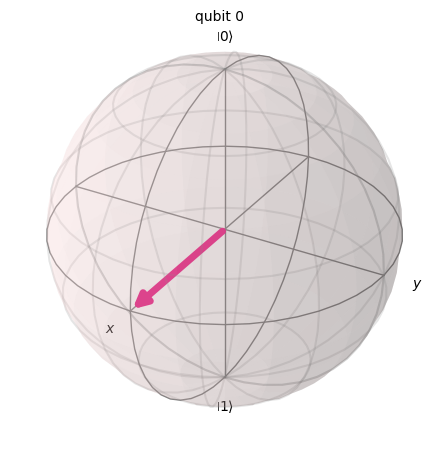

In [ ]:
# See the statevector
out_vector = Statevector(qc)
print(out_vector)

# Draw a Bloch sphere
plot_bloch_multivector(out_vector)

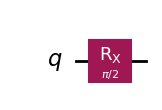

In [ ]:
from qiskit import QuantumCircuit
import numpy as np

# Create the single-qubit quantum circuit
qc = QuantumCircuit(1)

# Apply an Rx rotation gate to qubit 0 with an angle of pi/2
qc.rx(np.pi / 2, 0)

# Draw the circuit
qc.draw(output="mpl")


Statevector([0.70710678+0.j        , 0.        -0.70710678j],
            dims=(2,))


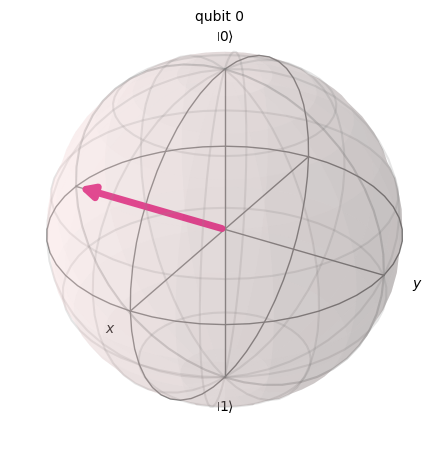

In [ ]:
# See the statevector
out_vector = Statevector(qc)
print(out_vector)

# Draw a Bloch sphere
plot_bloch_multivector(out_vector)

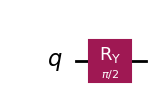

In [ ]:
from qiskit import QuantumCircuit
import numpy as np

# Create the single-qubit quantum circuit
qc = QuantumCircuit(1)

# Apply an Rx rotation gate to qubit 0 with an angle of pi/2
qc.ry(np.pi / 2, 0)

# Draw the circuit
qc.draw(output="mpl")


Statevector([0.70710678+0.j, 0.70710678+0.j],
            dims=(2,))


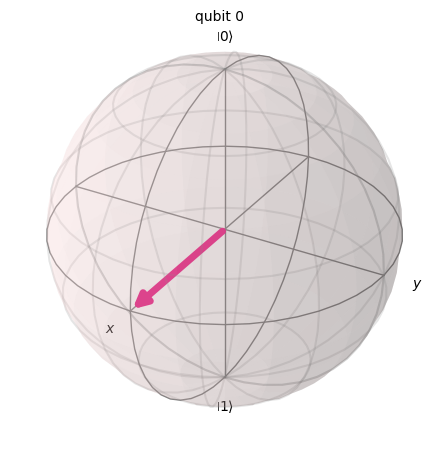

In [ ]:
# See the statevector
out_vector = Statevector(qc)
print(out_vector)

# Draw a Bloch sphere
plot_bloch_multivector(out_vector)

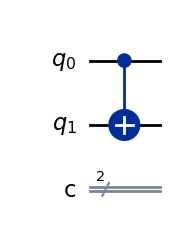

In [ ]:
# Initialize a circuit with 2 qubits and 2 classical bits for measurement
qc = QuantumCircuit(2, 2)



# 4. Controlled-NOT (CNOT / CX) Gate -> Control: Qubit 0, Target: Qubit 1
# This creates a quantum entangled state between the two qubits
qc.cx(0, 1)


# --- Matplotlib-based Drawing ---
# The return statement tells Jupyter to render the output cleanly as an inline image
qc.draw(output='mpl')

### Single-qubit quantum state and unitary evolution

The actions of all the gates we have seen so far have been *unitary*, which means they can be represented by a unitary operator. In other words, the output state can be obtained by acting on the initial state with a unitary matrix:

$$
|\psi^{'}\rangle = U|\psi\rangle
$$

A unitary matrix is a matrix satisfying

$$
U^{\dagger}U =U U^{\dagger} = I.
$$

In terms of quantum computer operation, we would say that applying a quantum gate to the qubit evolves the quantum state. Common single-qubit gates include the following.

Pauli gates:

$$
X = \begin{pmatrix}
0 & 1 \\
1 & 0 \\
\end{pmatrix}
= |0\rangle \langle 1|+|1\rangle \langle 0|
$$

$$
Y = \begin{pmatrix}
0 & -i \\
i & 0 \\
\end{pmatrix}
= -i|0\rangle \langle 1|+i|1\rangle \langle 0|
$$

$$
Z = \begin{pmatrix}
1 & 0 \\
0 & -1 \\
\end{pmatrix}
= |0\rangle \langle 0|-|1\rangle \langle 1|
$$

where the outer product was calculated as follows:

$$
|0\rangle \langle 0|=
\begin{bmatrix}
1 \\
0
\end{bmatrix}
\begin{bmatrix}
1 & 0
\end{bmatrix}
=\begin{bmatrix}
1 & 0 \\
0 & 0 \\
\end{bmatrix}, \quad
|1\rangle \langle 0|=
\begin{bmatrix}
0 \\
1
\end{bmatrix}
\begin{bmatrix}
1 & 0
\end{bmatrix}
=\begin{bmatrix}
0 & 0 \\
1 & 0 \\
\end{bmatrix}, \quad
$$

$$
|0\rangle \langle 1|=
\begin{bmatrix}
1 \\
0
\end{bmatrix}
\begin{bmatrix}
0 & 1
\end{bmatrix}
=\begin{bmatrix}
0 & 1 \\
0 & 0 \\
\end{bmatrix}, \quad
|1\rangle \langle 1|=
\begin{bmatrix}
0 \\
1
\end{bmatrix}
\begin{bmatrix}
0 & 1
\end{bmatrix}
=\begin{bmatrix}
0 & 0 \\
0 & 1 \\
\end{bmatrix}, \quad
$$

Other typical single-qubit gates:

$$
H= \frac{1}{\sqrt{2}}\begin{bmatrix}
1 & 1 \\
1 & -1 \\
\end{bmatrix},\quad
S = \begin{bmatrix}
1 & 0 \\
0 & i \\
\end{bmatrix}, \quad
T = \begin{bmatrix}
1 & 0 \\
0 & exp(i\pi/4) \\
\end{bmatrix}
$$

$$
R_x(\theta) = e^{-i\theta X/2} = cos\frac{\theta}{2}I - i sin \frac{\theta}{2}X = \begin{bmatrix}
cos\frac{\theta}{2} &  -i sin \frac{\theta}{2} \\
-i sin \frac{\theta}{2} & cos\frac{\theta}{2} \\
\end{bmatrix}
$$

$$
R_y(\theta) = e^{-i\theta Y/2} = cos\frac{\theta}{2}I - i sin \frac{\theta}{2}Y = \begin{bmatrix}
cos\frac{\theta}{2} &  - sin \frac{\theta}{2} \\
sin \frac{\theta}{2} & cos\frac{\theta}{2} \\
\end{bmatrix}
$$

$$
R_z(\theta) = e^{-i\theta Z/2} = cos\frac{\theta}{2}I - i sin \frac{\theta}{2}Z = \begin{bmatrix}
e^{-i\theta /2} &  0 \\
0 & e^{i\theta /2} \\
\end{bmatrix}
$$



## 3. Measurement

Measurement is theoretically a very complicated topic. But in practical terms, making a measurement along $z$ (as all IBM® quantum computers do) simply forces the qubit’s state $\alpha|0\rangle+\beta|1\rangle \quad (s.t.|\alpha|^2+|\beta|^2=1)$ either to $|0\rangle$ or to $|1\rangle$, and we observe the outcome.

* $|\alpha|^2$ is the probability we will get $|0\rangle$ when we measure.
* $|\beta|^2$ is the probability we will get $|1\rangle$ when we measure.

So, $\alpha$ and $\beta$ are called probability amplitudes. (see "Born rule")

For example, $\frac{\sqrt{2}}{2}|0\rangle+\frac{\sqrt{2}}{2}|1\rangle$ has an equal probability of becoming $|0\rangle$ or $|1\rangle$ upon measurement. $\frac{\sqrt{3}}{2}|0\rangle-\frac{1}{2}i|1\rangle$ has a 75% chance of becoming $|0\rangle$.


# Running a Quantum Circuit:
# The qiskit circuits are run on a ***BACKEND***.

# The instructions from qiskit (your input) should be translated to the language that a backend can understand quantum processing unit (QPU) understands.

# This software-to-hardware level translation is done by a ***TRANSPILER***.

# Different kind of backend we will use:
# 1. Noiseless backend (simulator)
# 2. Fake backend (has the characteristic of a real QPU, but it is like a snapshot taken at some previous time)
# 3. Real IBM QPU.

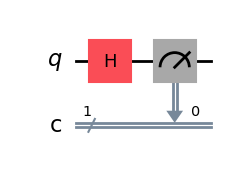

In [ ]:
# Create a new circuit with one qubits (first argument) and one classical bits (second argument)
qc = QuantumCircuit(1, 1)
qc.h(0)
qc.measure(0, 0)  # Add the measurement gate

qc.draw(output="mpl")

## We will use

##1. Noiseless simulator backend here (***AerSimulator***)

##2. Passmanager or transpiler. (here ***generate_preset_pass_manager*** transpiler).

## 3. ISA Circuits: Instruction Set Architectures

## [Most general, can be used for real QPUs as well]

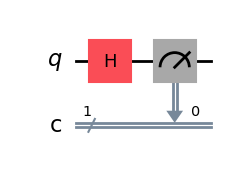

In [ ]:

from qiskit_aer import AerSimulator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager


# Run the circuit on a simulator to get the results
# Define backend
backend = AerSimulator()


# Transpile to backend
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_qc = pm.run(qc) #ISA: Instruction Set Architecture

isa_qc.draw(output="mpl")


# Sampler

## Sampling is a task that is based on the Born's interpretation of quantum mechanics.

### If you observe a quantum state which is in a state $| \psi \rangle = \frac{1}{\sqrt{2}} [|0 \rangle + | 1 \rangle]$, it will collapse to either state $| 0 \rangle$ or $| 1 \rangle$. A single observation (or circuit execution is called a "***SHOT***")


*   The probability of getting $| 0 \rangle = \frac{1}{2}$ is when you have INFINITE number of shots (ideal scenario).

* In real scenario, you CANNOT take infinite shots.

## A SAMPLER object helps you take the specified number of shots and provides the statistical description of the outcome.





{'0': 1}


/tmp/ipykernel_4433/3004929545.py:2: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


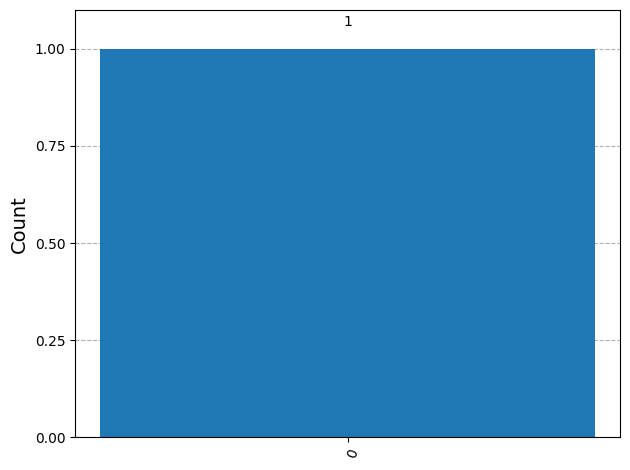

In [ ]:
# Run the job
sampler = SamplerV2(mode=backend)
job = sampler.run([isa_qc], shots=1)
result = job.result()

# Print the results
counts = result[0].data.c.get_counts()
print(counts)

# Plot the counts in a histogram
plot_histogram(counts)

{'0': 1, '1': 1}


/tmp/ipykernel_4433/2220699750.py:2: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


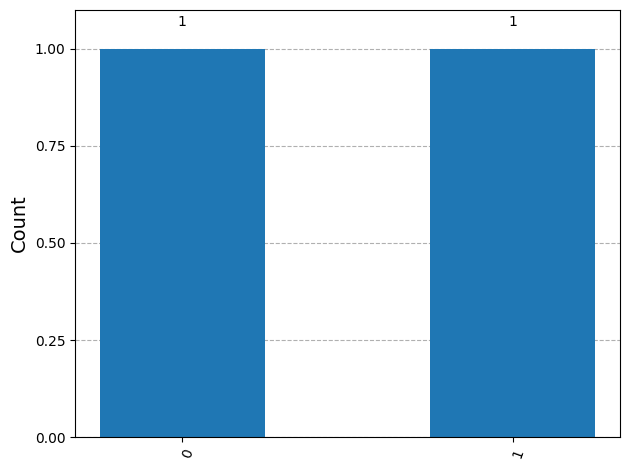

In [ ]:
# Run the job
sampler = SamplerV2(mode=backend)
job = sampler.run([isa_qc], shots=2)
result = job.result()

# Print the results
counts = result[0].data.c.get_counts()
print(counts)

# Plot the counts in a histogram
plot_histogram(counts)

{'0': 7, '1': 3}


/tmp/ipykernel_4433/3783352537.py:2: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


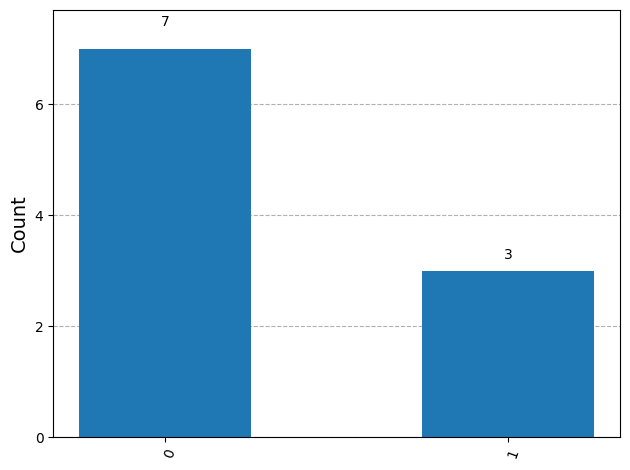

In [ ]:
# Run the job
sampler = SamplerV2(mode=backend)
job = sampler.run([isa_qc], shots=10)
result = job.result()

# Print the results
counts = result[0].data.c.get_counts()
print(counts)

# Plot the counts in a histogram
plot_histogram(counts)

/tmp/ipykernel_4433/3913555812.py:2: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


{'1': 44, '0': 56}


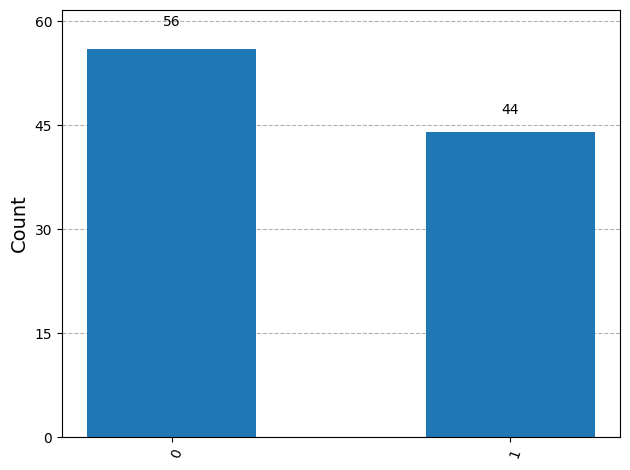

In [ ]:
# Run the job
sampler = SamplerV2(mode=backend)
job = sampler.run([isa_qc], shots=100)
result = job.result()

# Print the results
counts = result[0].data.c.get_counts()
print(counts)

# Plot the counts in a histogram
plot_histogram(counts)

/tmp/ipykernel_4433/421679219.py:2: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


{'0': 5038, '1': 4962}


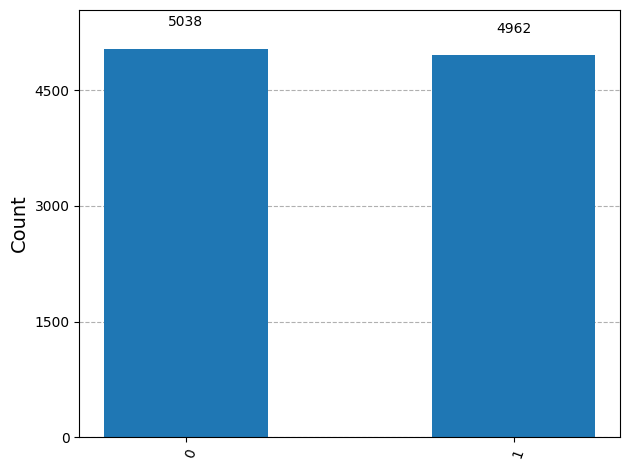

In [ ]:
# Run the job
sampler = SamplerV2(mode=backend)
job = sampler.run([isa_qc], shots=10000)
result = job.result()

# Print the results
counts = result[0].data.c.get_counts()
print(counts)

# Plot the counts in a histogram
plot_histogram(counts)

### You can see the probabilistic description of getting 50% probability of each state is only correct when the number of shots is high, with small number of shots, it may not be always 50-50

## Quantum Entanglement: Bell State Preparation

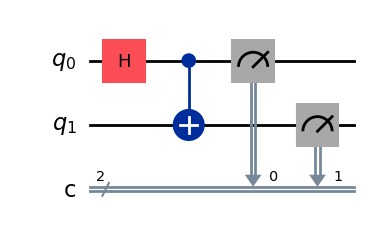

In [ ]:
# Initialize a circuit with 2 qubits and 2 classical bits for measurement
qc = QuantumCircuit(2, 2)



qc.h(0)
# 4. Controlled-NOT (CNOT / CX) Gate -> Control: Qubit 0, Target: Qubit 1
# This creates a quantum entangled state between the two qubits
qc.cx(0, 1)

# --- Add Measurement ---
# Map the quantum measurements to the classical bits [qubits], [classical_bits]
qc.measure([0, 1], [0, 1])




# --- Matplotlib-based Drawing ---
# The return statement tells Jupyter to render the output cleanly as an inline image
qc.draw(output='mpl')


/tmp/ipykernel_4433/767405200.py:6: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


{'11': 4960, '00': 5040}


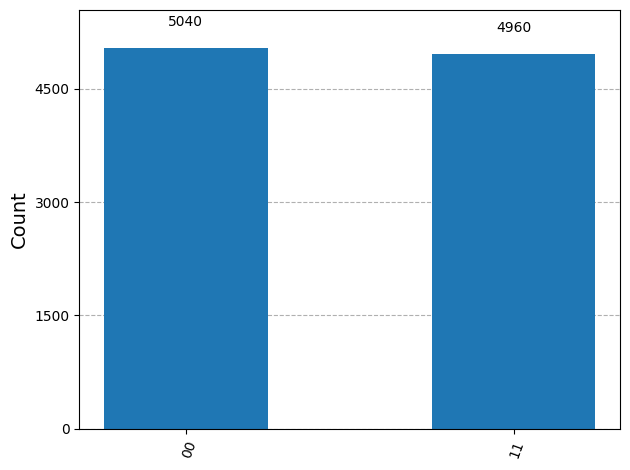

In [ ]:
# Transpile to backend
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_qc = pm.run(qc) #ISA: Instruction Set Architecture

# Run the job
sampler = SamplerV2(mode=backend)
job = sampler.run([isa_qc], shots=10000)
result = job.result()

# Print the results
counts = result[0].data.c.get_counts()
print(counts)

# Plot the counts in a histogram
plot_histogram(counts)

## 5. Running Circuits on a Fake Backend (contains **NOISE SIGNATURE**)

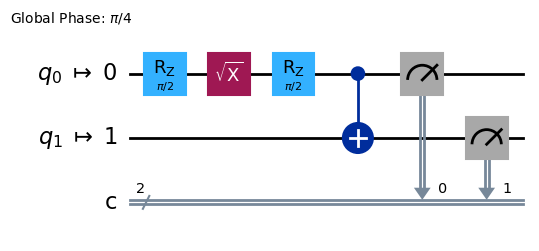

In [ ]:
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

# Get a fake backend from the fake provider
backend = FakeManilaV2()


qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])
#qc.draw(output='mpl')



# Transpile to backend
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_qc = pm.run(qc) #ISA: Instruction Set Architecture
isa_qc.draw(output='mpl')



/tmp/ipykernel_4433/4147869665.py:2: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


{'00': 4869, '11': 4535, '10': 328, '01': 268}


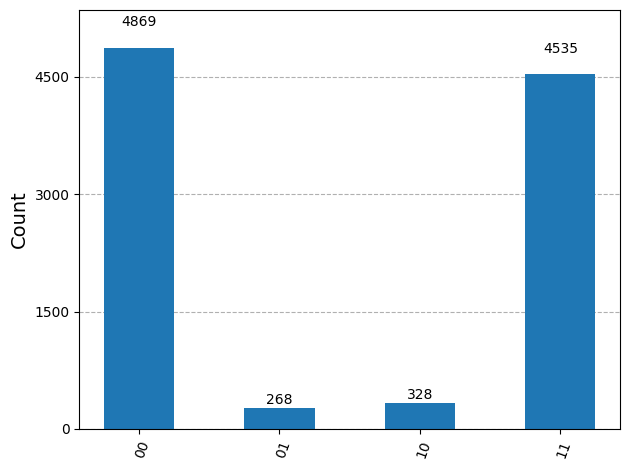

In [ ]:

# Run the job
sampler = SamplerV2(mode=backend)
job = sampler.run([isa_qc], shots=10000)



result = job.result()

# Print the results
counts = result[0].data.c.get_counts()
print(counts)

# Plot the counts in a histogram
plot_histogram(counts)


Some observations collapse to "ILLEGAL" states $| 01 \rangle$ and $| 10 \rangle$ due to noise.

# 6. Expectation value of Observables:

Estimator objects from Qiskit are used for getting the expectation values of an observable



### < Mathematical Framework of the Estimator Primitive >

### Expectation value of $Z$ operator with $| + \rangle = \frac{1}{\sqrt{2}}( |0 \rangle + | 1 \rangle)$ state.

### Ideal Mathematical Derivation for $\langle Z \rangle = 0.0$

The infinite-shot, exact mathematical expectation value for a qubit prepared in the $|+\rangle$ superposition state evaluated under the Pauli-Z operator is precisely $0.0$. Here is the step-by-step vector mechanics proof:

---

#### 1. State Vector Assembly
The Hadamard ($H$) gate transforms the ground computational base vector $|0\rangle$ into a balanced $50/50$ phase split state vector $|\psi\rangle$:

$$|\psi\rangle = H|0\rangle = \frac{1}{\sqrt{2}}|0\rangle + \frac{1}{\sqrt{2}}|1\rangle = \begin{pmatrix} \frac{1}{\sqrt{2}} \\ \frac{1}{\sqrt{2}} \end{pmatrix}$$

---

#### 2. Operation of the Pauli-Z Matrix
The Pauli-Z matrix leaves the $|0\rangle$ state untouched while executing a $180^\circ$ phase inversion (sign flip) directly on the $|1\rangle$ component:

$$Z|\psi\rangle = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix} \begin{pmatrix} \frac{1}{\sqrt{2}} \\ \frac{1}{\sqrt{2}} \end{pmatrix} = \begin{pmatrix} \frac{1}{\sqrt{2}} \\ -\frac{1}{\sqrt{2}} \end{pmatrix} = \frac{1}{\sqrt{2}}|0\rangle - \frac{1}{\sqrt{2}}|1\rangle$$

---

#### 3. Resolving the Inner Product
The true expectation scalar value $\langle Z \rangle$ is mapped by multiplying the complex conjugate row vector (the bra $\langle \psi |$) across our operated column state ($Z|\psi\rangle$):

$$\langle Z \rangle = \langle \psi | Z | \psi \rangle = \begin{pmatrix} \frac{1}{\sqrt{2}} & \frac{1}{\sqrt{2}} \end{pmatrix} \begin{pmatrix} \frac{1}{\sqrt{2}} \\ -\frac{1}{\sqrt{2}} \end{pmatrix}$$

$$\langle Z \rangle = \left(\frac{1}{\sqrt{2}} \cdot \frac{1}{\sqrt{2}}\right) + \left(\frac{1}{\sqrt{2}} \cdot -\frac{1}{\sqrt{2}}\right)$$

$$\langle Z \rangle = \frac{1}{2} - \frac{1}{2} = \mathbf{0.0}$$

---

#### 💡 Probability-Weight Perspective (Born Rule)
Alternatively, using discrete eigenvalues, the system resolves identically. The individual eigenvalues for the Z operator are $+1$ (for $|0\rangle$) and $-1$ (for $|1\rangle$). By parsing these via their ideal Born Rule probabilities ($P(0) = 0.5$, $P(1) = 0.5$):

$$\langle Z \rangle = P(0)(+1) + P(1)(-1)$$

$$\langle Z \rangle = (0.5)(1) + (0.5)(-1) = \mathbf{0.0}$$

Because the probability weights are completely symmetric, the outcomes perfectly cancel each other out over an infinite sequence of measurements.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime.executor_estimator import Estimator



backend = AerSimulator()
# 1. Map out a state with maximum variance (The |+> superposition state)
# In this state, measuring the Z operator yields a 50% chance of +1 and 50% chance of -1
qc = QuantumCircuit(1)
qc.h(0)

# 2. Set our targeted tracking variable to the Pauli-Z operator
observable = SparsePauliOp(["Z"])

# 3. Define a varying array of shot sizes to compare
shot_sizes = [1, 5, 20, 100, 1000, 10000, 50000, 1000000]
calculated_exp_values = []

# 4. Loop through each shot configuration to observe statistical drift
for shots in shot_sizes:

    estimator = Estimator(mode=backend, options={"default_shots": shots})
    # Convert shot counts into precision bounds: Precision = 1 / sqrt(shots)
#    precision_target = 1.0 / np.sqrt(shots)

    # Initialize the Aer Estimator for sampling simulation
    #estimator = EstimatorV2()

    # Run the PUB block passing the calculated precision boundary
    job = estimator.run([(qc, observable)])
    result = job.result()

    # Save the resulting expectation value
    calculated_exp_values.append(result[0].data.evs)

# --- 5. Clean Terminal Text Output ---
print(f"Ideal Mathematical Expectation Value <Z>: 0.0\n")
for s, val in zip(shot_sizes, calculated_exp_values):
    print(f"Shots: {s:<6} | Observed Expectation Value <Z>: {val:+.4f}")


Ideal Mathematical Expectation Value <Z>: 0.0

Shots: 1      | Observed Expectation Value <Z>: -0.1875
Shots: 5      | Observed Expectation Value <Z>: -0.0625
Shots: 20     | Observed Expectation Value <Z>: +0.0625
Shots: 100    | Observed Expectation Value <Z>: -0.0938
Shots: 1000   | Observed Expectation Value <Z>: +0.0332
Shots: 10000  | Observed Expectation Value <Z>: -0.0010
Shots: 50000  | Observed Expectation Value <Z>: +0.0062
Shots: 1000000 | Observed Expectation Value <Z>: +0.0007


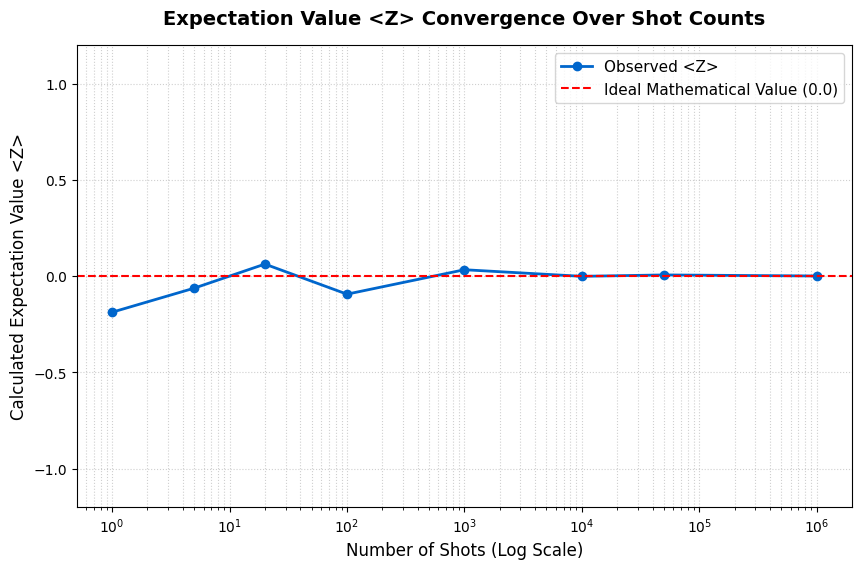

In [ ]:
# --- 5. Inline Matplotlib Plotting Engine ---
plt.figure(figsize=(10, 6))

# Plot the calculated data points and connect them with a line
plt.plot(shot_sizes, calculated_exp_values, marker='o', color='#0066cc', linewidth=2, label='Observed <Z>')

# Draw a static red reference line representing the perfect infinite-shot ideal value
plt.axhline(y=0.0, color='r', linestyle='--', linewidth=1.5, label='Ideal Mathematical Value (0.0)')

# Use a logarithmic scale for the X-axis because shot sizes jump from 1 to 50,000
plt.xscale('log')

# Label formatting
plt.title('Expectation Value <Z> Convergence Over Shot Counts', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Shots (Log Scale)', fontsize=12)
plt.ylabel('Calculated Expectation Value <Z>', fontsize=12)
plt.ylim(-1.2, 1.2) # Bound Y to display the full physical window of the Z operator
plt.grid(True, which="both", linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc='upper right')

# Render the plot inside the notebook
plt.show()

In [ ]:
!pip install qiskit_nature
!pip install pyscf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 11.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 10.0 MB/s  0:00:05


### 7. Jordan-Wigner (JW) Mapping: Mathematical Derivation of the JW Code Examples

The Jordan-Wigner (JW) transformation maps fermionic creation ($a_j^\dagger$) and annihilation ($a_j$) operators to qubit Pauli operators. The general transformation identities are defined as:

$$a_j^\dagger = \left( \prod_{k < j} -Z_k \right) \otimes \sigma_j^+ = \left( \prod_{k < j} -Z_k \right) \otimes \frac{X_j - iY_j}{2}$$

$$a_j = \left( \prod_{k < j} -Z_k \right) \otimes \sigma_j^- = \left( \prod_{k < j} -Z_k \right) \otimes \frac{X_j + iY_j}{2}$$

Where the trailing Pauli-Z sequence ($\prod -Z_k$) represents the **Jordan-Wigner String**, which physically tracks the non-local phase sign changes caused by swapping antisymmetric fermions.

---

#### 1. Example A: The Number Operator ($a_0^\dagger a_0$)
The number operator counts the electron occupancy of orbital index $0$. Because $j = 0$, the set of preceding indices $\{k < 0\}$ is completely empty, causing the Jordan-Wigner string to reduce to the identity matrix ($I$).

Substituting the definition directly:

$$a_0^\dagger a_0 = \left( \frac{X_0 - iY_0}{2} \right) \left( \frac{X_0 + iY_0}{2} \right)$$

$$a_0^\dagger a_0 = \frac{1}{4} \left( X_0^2 + iX_0Y_0 - iY_0X_0 + Y_0^2 \right)$$

Using the algebraic properties of Pauli matrices ($X^2 = Y^2 = I$, and $XY = -YX = iZ$):

$$a_0^\dagger a_0 = \frac{1}{4} \left( I + i(iZ_0) - i(-iZ_0) + I \right) = \frac{1}{4} \left( 2I - 2Z_0 \right)$$

$$a_0^\dagger a_0 = \frac{I - Z_0}{2} = 0.5 \cdot I - 0.5 \cdot Z_0$$

This matches the exact output string `0.5 * II - 0.5 * IZ` generated by the Qiskit code.

---

#### 2. Example B: The Hopping Operator ($a_1^\dagger a_0$)
The hopping operator tracks a physical transition where an electron hops from orbital $0$ to orbital $1$.

* For index $j = 0$: The JW string is empty $\rightarrow a_0 = \sigma_0^- = \frac{X_0 + iY_0}{2}$
* For index $j = 1$: The index $k = 0$ precedes it, introducing a single $-Z_0$ string layer $\rightarrow a_1^\dagger = -Z_0 \otimes \sigma_1^+ = -Z_0 \otimes \frac{X_1 - iY_1}{2}$

Multiplying the two operators together under Little-Endian formatting ($q_1 \otimes q_0$):

$$a_1^\dagger a_0 = \left( -Z_0 \otimes \frac{X_1 - iY_1}{2} \right) \cdot \left( I_1 \otimes \frac{X_0 + iY_0}{2} \right)$$

Grouping the terms acting on identical qubit indices together:

$$a_1^\dagger a_0 = \frac{1}{4} (X_1 - iY_1)I_1 \otimes (-Z_0)(X_0 + iY_0)$$

Using the Pauli algebraic relation where matrix multiplication maps directly to a phase shift ($ZX = iY$ and $ZY = -iX$):

$$-Z_0 X_0 = -iY_0 \quad \text{and} \quad -Z_0 Y_0 = iX_0$$

Substituting these back into the tensor expression:

$$a_1^\dagger a_0 = \frac{1}{4} (X_1 - iY_1) \otimes (-iY_0 - X_0)$$

Expanding out the distributed algebraic products:

$$a_1^\dagger a_0 = \frac{1}{4} \left( -X_1 X_0 - iX_1 Y_0 + iY_1 X_0 - Y_1 Y_0 \right)$$

$$a_1^\dagger a_0 = -\frac{1}{4}(X_1 X_0 + Y_1 Y_0) + \frac{i}{4}(Y_1 X_0 - X_1 Y_0)$$

This explains why the hopping output in the code generates a matrix composed of cross-paired $XX$, $YY$, $YX$, and $XY$ components to structurally track the fermionic movement between the two system indices.


In [ ]:
# Make sure you have installed qiskit-nature: pip install qiskit-nature
from qiskit_nature.second_q.operators import FermionicOp
from qiskit_nature.second_q.mappers import JordanWignerMapper

# 1. Define Fermionic Operators using standard string notation
# "+_0" means: Create a fermion in orbital 0 (a_0^\dagger)
# "-_1" means: Destroy a fermion in orbital 1 (a_1)
print("--- 1. Creating Fermionic Operators ---")

# Example A: A number operator (a_0^\dagger a_0) tracking if orbital 0 is occupied
f_number = FermionicOp({"+_0 -_0": 1.0})
print("Fermionic Number Operator:\n", f_number)

# Example B: A hopping operator (a_1^\dagger a_0) tracking an electron jumping from orbital 0 to 1
f_hop = FermionicOp({"+_1 -_0": 1.0})
print("\nFermionic Hopping Operator:\n", f_hop)


# 2. Initialize the Jordan-Wigner Mapper
mapper = JordanWignerMapper()


# 3. Translate the Fermionic operators into Qubit operators (SparsePauliOp)
print("\n--- 2. Executing Jordan-Wigner Mapping ---")

qubit_number = mapper.map(f_number)
print("Qubit Number Operator Matrix:\n", qubit_number)

qubit_hop = mapper.map(f_hop)
print("\nQubit Hopping Operator Matrix:\n", qubit_hop)


--- 1. Creating Fermionic Operators ---
Fermionic Number Operator:
 Fermionic Operator
number spin orbitals=1, number terms=1
  1.0 * ( +_0 -_0 )

Fermionic Hopping Operator:
 Fermionic Operator
number spin orbitals=2, number terms=1
  1.0 * ( +_1 -_0 )

--- 2. Executing Jordan-Wigner Mapping ---
Qubit Number Operator Matrix:
 SparsePauliOp(['I', 'Z'],
              coeffs=[ 0.5+0.j, -0.5+0.j])

Qubit Hopping Operator Matrix:
 SparsePauliOp(['XY', 'XX', 'YY', 'YX'],
              coeffs=[0.  +0.25j, 0.25+0.j  , 0.25+0.j  , 0.  -0.25j])


# 8. Solving Schrodinger Equations for Molecular Problem with Quantum Computers

In [ ]:
from qiskit import QuantumCircuit
from qiskit.circuit.library import EvolvedOperatorAnsatz
from qiskit.quantum_info import Statevector
from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_nature.second_q.operators import FermionicOp

problem = PySCFDriver(atom="H 0 0 0; H 0 0 0.735", basis="sto3g",
                      unit=DistanceUnit.ANGSTROM).run()


num_particles = problem.num_particles
num_alpha_particles = num_particles[0]
num_beta_particles = num_particles[1]
num_total_particles = num_alpha_particles + num_beta_particles
num_spin_orbitals = problem.num_spin_orbitals
num_spatial_orbitals = problem.num_spatial_orbitals
nuclear_repulsion_energy = problem.nuclear_repulsion_energy
orbital_energy_spatial = list(problem.orbital_energies)

print(len(orbital_energy_spatial))

oe = orbital_energy_spatial + orbital_energy_spatial
alpha_occupations = problem.orbital_occupations
beta_occupations = problem.orbital_occupations_b

print('number of particles:                   ', num_particles)
print('number of alpha spin particles         ', num_alpha_particles)
print('number of beta spin particles         ', num_beta_particles)
print('total number of particles              ', num_total_particles)
print('number of spin orbitals:               ', num_spin_orbitals)
print('nuclear repulsion energy:              ', nuclear_repulsion_energy)
print('orbital energy spatial:                ', orbital_energy_spatial)
print(oe)


2
number of particles:                    (1, 1)
number of alpha spin particles          1
number of beta spin particles          1
total number of particles               2
number of spin orbitals:                4
nuclear repulsion energy:               0.7199689944489797
orbital energy spatial:                 [np.float64(-0.5806289181997337), np.float64(0.6763362534452197)]
[np.float64(-0.5806289181997337), np.float64(0.6763362534452197), np.float64(-0.5806289181997337), np.float64(0.6763362534452197)]


In [ ]:
mapper = JordanWignerMapper()



hamiltonian_sq = problem.hamiltonian.second_q_op()

print (hamiltonian_sq)



Fermionic Operator
number spin orbitals=4, number terms=36
  -1.25633907300325 * ( +_0 -_0 )
+ -0.47189600728114184 * ( +_1 -_1 )
+ -1.25633907300325 * ( +_2 -_2 )
+ -0.47189600728114184 * ( +_3 -_3 )
+ 0.33785507740175813 * ( +_0 +_0 -_0 -_0 )
+ 0.33229086512764816 * ( +_0 +_1 -_1 -_0 )
+ 0.33785507740175813 * ( +_0 +_2 -_2 -_0 )
+ 0.33229086512764816 * ( +_0 +_3 -_3 -_0 )
+ 0.0904655998921157 * ( +_0 +_0 -_1 -_1 )
+ 0.0904655998921157 * ( +_0 +_1 -_0 -_1 )
+ 0.0904655998921157 * ( +_0 +_2 -_3 -_1 )
+ 0.0904655998921157 * ( +_0 +_3 -_2 -_1 )
+ 0.0904655998921157 * ( +_1 +_0 -_1 -_0 )
+ 0.0904655998921157 * ( +_1 +_1 -_0 -_0 )
+ 0.0904655998921157 * ( +_1 +_2 -_3 -_0 )
+ 0.0904655998921157 * ( +_1 +_3 -_2 -_0 )
+ 0.33229086512764816 * ( +_1 +_0 -_0 -_1 )
+ 0.34928686136600906 * ( +_1 +_1 -_1 -_1 )
+ 0.33229086512764816 * ( +_1 +_2 -_2 -_1 )
+ 0.34928686136600906 * ( +_1 +_3 -_3 -_1 )
+ 0.33785507740175813 * ( +_2 +_0 -_0 -_2 )
+ 0.33229086512764816 * ( +_2 +_1 -_1 -_2 )
+ 0.33785507740

In [ ]:
H = mapper.map(problem.hamiltonian.second_q_op())

print (H)

SparsePauliOp(['IIII', 'IIIZ', 'IIZI', 'IZII', 'ZIII', 'IIZZ', 'IZIZ', 'ZIIZ', 'YYYY', 'XXYY', 'YYXX', 'XXXX', 'IZZI', 'ZIZI', 'ZZII'],
              coeffs=[-0.81054798+0.j,  0.17218393+0.j, -0.22575349+0.j,  0.17218393+0.j,
 -0.22575349+0.j,  0.12091263+0.j,  0.16892754+0.j,  0.16614543+0.j,
  0.0452328 +0.j,  0.0452328 +0.j,  0.0452328 +0.j,  0.0452328 +0.j,
  0.16614543+0.j,  0.17464343+0.j,  0.12091263+0.j])


Parameterized Quantum Circuits (PQC)

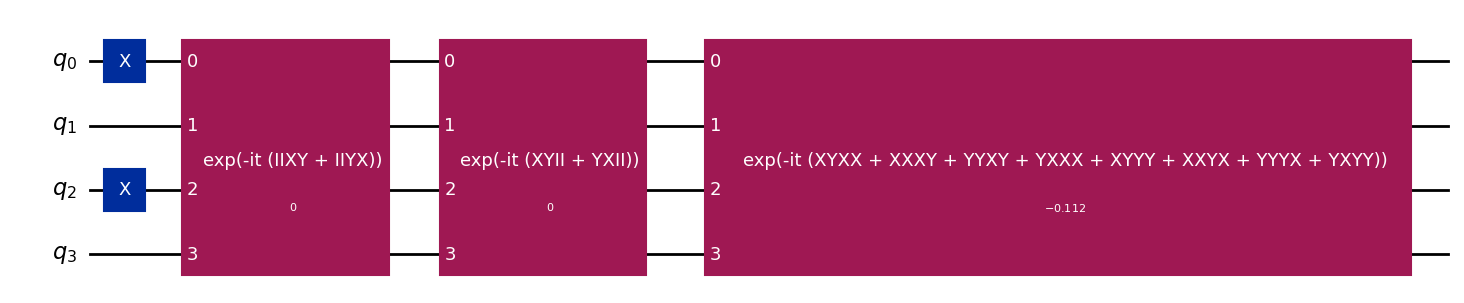

In [ ]:
n = problem.num_spin_orbitals

init_state = QuantumCircuit(n)
init_state.x([0, 2])                                     # HF |0101>

excitations = [
    FermionicOp({"+_1 -_0": 1, "+_0 -_1": -1}, num_spin_orbitals=n),                   # 0a -> 1a
    FermionicOp({"+_3 -_2": 1, "+_2 -_3": -1}, num_spin_orbitals=n),                   # 0b -> 1b
    FermionicOp({"+_1 +_3 -_2 -_0": 1, "+_0 +_2 -_3 -_1": -1}, num_spin_orbitals=n),  # 0a0b -> 1a1b
]
adapt_excitation_list_pauli = [(1j * mapper.map(T)).simplify() for T in excitations]  # Hermitian i(T - T^dag)

optimal_params_so_far = [0.0, 0.0, -0.111768]

new_init_state = EvolvedOperatorAnsatz(adapt_excitation_list_pauli,
                                       initial_state=init_state).assign_parameters(optimal_params_so_far)

new_init_state.decompose().draw(output='mpl')
#E = Statevector(new_init_state).expectation_value(H).real + problem.nuclear_repulsion_energy
#print(f"E = {E:.8f} Ha")